# Vehicle Price Prediction using XGBoost Regression
**Student Roll Number:** 241FA18229  
**Dataset:** Vehicle Dataset from CarDekho (`nehalbirla/vehicle-dataset-from-cardekho`)  
**Objective:** Build, tune, and evaluate an end-to-end Machine Learning pipeline using XGBoost with log-transformed target regression.

### 1. Import Required Libraries

In [1]:
from pathlib import Path
from datetime import datetime
import re
import shutil

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import xgboost as xgb
from xgboost import XGBRegressor

print('Libraries imported successfully!')
print(f'Pandas version      : {pd.__version__}')
print(f'NumPy version       : {np.__version__}')
print(f'Scikit-learn version: {sklearn.__version__}')
print(f'XGBoost version     : {xgb.__version__}')

Libraries imported successfully!
Pandas version      : 2.3.2
NumPy version       : 2.2.6
Scikit-learn version: 1.7.2
XGBoost version     : 3.2.0


### 2. Experiment Configuration & Paths

In [2]:
DATASET_HANDLE = 'nehalbirla/vehicle-dataset-from-cardekho'
RANDOM_STATE = 42
FULL_DATA_OUTPUT = Path('cardekho_full.csv')
RESULTS_OUTPUT = Path('random_forest_experiment_results.csv')
MODEL_OUTPUT = Path('best_xgboost_model.joblib')
RESULTS_TEXT_OUTPUT = Path('xgboost_hyperparameter_results.txt')

print('Experiment Configuration:')
print(f'  Dataset Handle     : {DATASET_HANDLE}')
print(f'  Random State       : {RANDOM_STATE}')
print(f'  Dataset Path       : {FULL_DATA_OUTPUT}')
print(f'  Model Output File  : {MODEL_OUTPUT}')
print(f'  Results Output File: {RESULTS_TEXT_OUTPUT}')

Experiment Configuration:
  Dataset Handle     : nehalbirla/vehicle-dataset-from-cardekho
  Random State       : 42
  Dataset Path       : cardekho_full.csv
  Model Output File  : best_xgboost_model.joblib
  Results Output File: xgboost_hyperparameter_results.txt


### 3. Utility & Helper Functions

In [3]:
def find_csv(dataset_path: str) -> Path:
	csv_files = list(Path(dataset_path).rglob('*.csv'))
	if not csv_files:
		raise FileNotFoundError(f'No CSV file found in {dataset_path}')

	preferred_names = {'car data.csv', 'cardekho.csv'}
	return next(
		(file for file in csv_files if file.name.lower() in preferred_names),
		csv_files[0],
	)

def numeric_value(value: object) -> float:
	if pd.isna(value):
		return float('nan')
	match = re.search(r'[-+]?\d*\.?\d+', str(value).replace(',', ''))
	return float(match.group()) if match else float('nan')

print('Helper functions registered: find_csv(), numeric_value()')

Helper functions registered: find_csv(), numeric_value()


### 4. Load and Inspect Raw Dataset

In [4]:
csv_path = Path('cardekho_full.csv')
if not csv_path.exists():
    csv_path = Path('data/raw/cardekho_full.csv')

raw_df = pd.read_csv(csv_path)
print(f'Dataset successfully loaded from: {csv_path}')
print(f'Total Rows: {raw_df.shape[0]}, Total Columns: {raw_df.shape[1]}\n')
print('Column Data Types:')
print(raw_df.dtypes)
print('\nFirst 5 Records:')
display(raw_df.head())

Dataset successfully loaded from: cardekho_full.csv
Total Rows: 301, Total Columns: 9

Column Data Types:
Car_Name          object
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type         object
Seller_Type       object
Transmission      object
Owner              int64
dtype: object

First 5 Records:


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


### 5. Data Cleaning & Feature Engineering

In [5]:
def prepare_data(data: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
	data = data.copy()
	data.columns = data.columns.str.strip().str.lower().str.replace(' ', '_', regex=False)

	target_candidates = ['selling_price', 'price']
	target = next((column for column in target_candidates if column in data), None)
	if target is None:
		raise KeyError("The CSV must contain a 'selling_price' or 'price' column.")

	for column in ('mileage', 'engine', 'max_power'):
		if column in data:
			data[column] = data[column].map(numeric_value)

	if 'year' in data:
		data['vehicle_age'] = datetime.now().year - pd.to_numeric(data['year'], errors='coerce')
		data = data.drop(columns='year')
	else:
		raise KeyError("The CSV must contain a 'year' column to create vehicle_age.")

	y = pd.to_numeric(data.pop(target), errors='coerce')
	valid_rows = y.notna() & (y > 0)
	data = data.loc[valid_rows].reset_index(drop=True)
	y = y.loc[valid_rows].reset_index(drop=True)

	data = data.drop(columns=['name', 'car_name', 'torque'], errors='ignore')
	categorical_columns = [
		'fuel',
		'fuel_type',
		'seller_type',
		'transmission',
		'owner',
	]
	categorical_columns = [column for column in categorical_columns if column in data]
	numeric_columns = [column for column in data.columns if column not in categorical_columns]

	for column in numeric_columns:
		data[column] = pd.to_numeric(data[column], errors='coerce')

	return data, y

X, y = prepare_data(raw_df)
print('Data Preparation Summary:')
print(f'  Features (X) Shape: {X.shape}')
print(f'  Target (y) Shape  : {y.shape}')
print(f'  Missing Values in Features:\n{X.isna().sum()[X.isna().sum() > 0]}')
print('\nProcessed Feature Samples:')
display(X.head())

Data Preparation Summary:
  Features (X) Shape: (301, 7)
  Target (y) Shape  : (301,)
  Missing Values in Features:
Series([], dtype: int64)

Processed Feature Samples:


,present_price,kms_driven,fuel_type,seller_type,transmission,owner,vehicle_age
0,5.59,27000,Petrol,Dealer,Manual,0,12
1,9.54,43000,Diesel,Dealer,Manual,0,13
2,9.85,6900,Petrol,Dealer,Manual,0,9
3,4.15,5200,Petrol,Dealer,Manual,0,15
4,6.87,42450,Diesel,Dealer,Manual,0,12


### 6. Train-Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
	X, y, test_size=0.2, random_state=RANDOM_STATE
)
print('Train-Test Split Partition:')
print(f'  Training Records: {X_train.shape[0]} (80%)')
print(f'  Testing Records : {X_test.shape[0]} (20%)')
print(f'  Number of Features: {X_train.shape[1]}')
print('\nTarget Variable Statistics (Training Set):')
print(y_train.describe())

Train-Test Split Partition:
  Training Records: 240 (80%)
  Testing Records : 61 (20%)
  Number of Features: 7

Target Variable Statistics (Training Set):
count    240.000000
mean       4.642292
std        5.152443
min        0.100000
25%        0.772500
50%        3.500000
75%        5.950000
max       35.000000
Name: selling_price, dtype: float64


### 7. Scikit-Learn Preprocessing Pipeline

In [7]:
def build_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
	categorical_columns = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
	numeric_columns = X.select_dtypes(exclude=['object', 'category', 'string']).columns.tolist()

	numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median'))])
	categorical_pipeline = Pipeline(
		[
			('imputer', SimpleImputer(strategy='most_frequent')),
			('encoder', OneHotEncoder(handle_unknown='ignore')),
		]
	)
	return ColumnTransformer(
		[
			('numeric', numeric_pipeline, numeric_columns),
			('categorical', categorical_pipeline, categorical_columns),
		]
	)

preprocessor = build_preprocessor(X_train)
print('Preprocessing Architecture:')
print('  Numeric Pipeline    : SimpleImputer(strategy="median")')
print('  Categorical Pipeline: SimpleImputer(strategy="most_frequent") + OneHotEncoder(handle_unknown="ignore")')
print('\nNumeric Features    :', X_train.select_dtypes(exclude=['object', 'category', 'string']).columns.tolist())
print('Categorical Features:', X_train.select_dtypes(include=['object', 'category', 'string']).columns.tolist())
preprocessor

Preprocessing Architecture:
  Numeric Pipeline    : SimpleImputer(strategy="median")
  Categorical Pipeline: SimpleImputer(strategy="most_frequent") + OneHotEncoder(handle_unknown="ignore")

Numeric Features    : ['present_price', 'kms_driven', 'owner', 'vehicle_age']
Categorical Features: ['fuel_type', 'seller_type', 'transmission']


,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


### 8. End-to-End XGBoost Pipeline (Log-Target Regression)

In [8]:
def build_xgboost_pipeline(X_train: pd.DataFrame) -> Pipeline:
	return Pipeline(
		[
			('preprocessor', build_preprocessor(X_train)),
			(
				'model',
				TransformedTargetRegressor(
					regressor=XGBRegressor(
						objective='reg:squarederror',
						random_state=RANDOM_STATE,
						n_jobs=-1,
						eval_metric='rmse',
					),
					func=np.log1p,
					inverse_func=np.expm1,
				)
			),
		]
	)

pipeline = build_xgboost_pipeline(X_train)
print('XGBoost Regressor Pipeline constructed with TransformedTargetRegressor [log1p / expm1]:')
pipeline

XGBoost Regressor Pipeline constructed with TransformedTargetRegressor [log1p / expm1]:


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### 9. Hyperparameter Tuning via RandomizedSearchCV

In [9]:
def tune_xgboost(X_train: pd.DataFrame, y_train: pd.Series, X_test: pd.DataFrame, y_test: pd.Series) -> tuple[Pipeline, dict, dict]:
	pipeline = build_xgboost_pipeline(X_train)
	param_distributions = {
		'model__regressor__n_estimators': [300, 500, 800, 1000],
		'model__regressor__max_depth': [3, 5, 7, 9],
		'model__regressor__learning_rate': [0.01, 0.05, 0.1],
		'model__regressor__subsample': [0.7, 0.8, 1.0],
		'model__regressor__colsample_bytree': [0.7, 0.8, 1.0],
		'model__regressor__min_child_weight': [1, 3, 5],
		'model__regressor__gamma': [0, 0.1, 0.2],
	}

	search = RandomizedSearchCV(
		estimator=pipeline,
		param_distributions=param_distributions,
		n_iter=50,
		cv=3,
		scoring='r2',
		random_state=RANDOM_STATE,
		n_jobs=-1,
		verbose=0,
	)
	search.fit(X_train, y_train)
	best_pipeline = search.best_estimator_
	predictions = best_pipeline.predict(X_test)
	metrics = {
		'Best R2': r2_score(y_test, predictions),
		'Best MAE': mean_absolute_error(y_test, predictions),
		'Best RMSE': mean_squared_error(y_test, predictions) ** 0.5,
	}
	return best_pipeline, search.best_params_, metrics

print('Executing RandomizedSearchCV (50 iterations, 3-fold CV)...')
best_pipeline, best_params, metrics = tune_xgboost(X_train, y_train, X_test, y_test)
print('\nOptimal Hyperparameters Selected:')
for param, val in best_params.items():
    print(f'  {param:35}: {val}')

Executing RandomizedSearchCV (50 iterations, 3-fold CV)...



Optimal Hyperparameters Selected:
  model__regressor__subsample        : 0.7
  model__regressor__n_estimators     : 800
  model__regressor__min_child_weight : 1
  model__regressor__max_depth        : 3
  model__regressor__learning_rate    : 0.05
  model__regressor__gamma            : 0
  model__regressor__colsample_bytree : 0.8


### 10. Test Set Evaluation & Performance Metrics

In [10]:
print('====================================================')
print('        XGBOOST TEST SET PERFORMANCE EVALUATION     ')
print('====================================================')
results_table = pd.DataFrame([
    {'Metric': 'R² Score (Coefficient of Determination)', 'Value': f'{metrics["Best R2"]:.6f}'},
    {'Metric': 'Mean Absolute Error (MAE)', 'Value': f'{metrics["Best MAE"]:.6f}'},
    {'Metric': 'Root Mean Squared Error (RMSE)', 'Value': f'{metrics["Best RMSE"]:.6f}'}
])
display(results_table)
print(f'\nSummary: The tuned XGBoost model explains {metrics["Best R2"]*100:.2f}% of price variance.')

        XGBOOST TEST SET PERFORMANCE EVALUATION     


,Metric,Value
0,R² Score (Coefficient of Determination),0.958109
1,Mean Absolute Error (MAE),0.565714
2,Root Mean Squared Error (RMSE),0.982334



Summary: The tuned XGBoost model explains 95.81% of price variance.


### 11. Visualization: True vs. Predicted Vehicle Prices

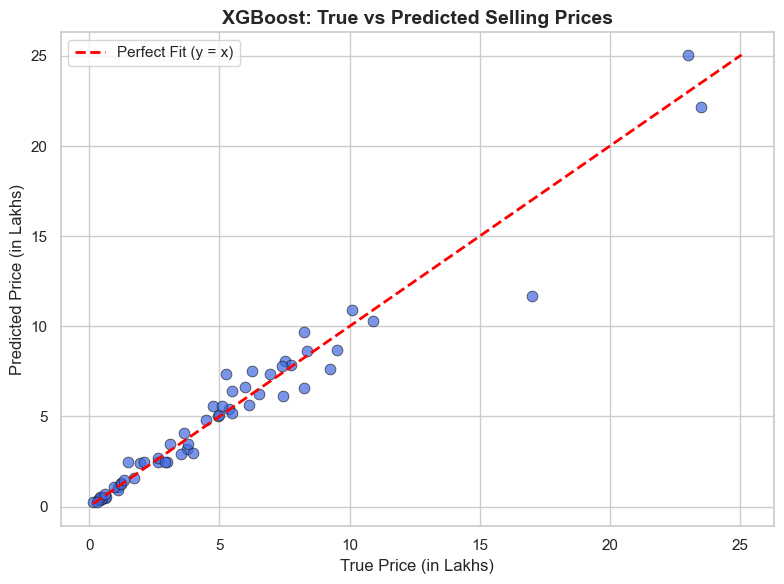

In [11]:
sns.set_theme(style='whitegrid')
predictions = best_pipeline.predict(X_test)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=predictions, alpha=0.7, color='royalblue', s=60, edgecolor='k')

min_val = min(y_test.min(), predictions.min())
max_val = max(y_test.max(), predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Fit (y = x)')

plt.title('XGBoost: True vs Predicted Selling Prices', fontsize=14, fontweight='bold')
plt.xlabel('True Price (in Lakhs)', fontsize=12)
plt.ylabel('Predicted Price (in Lakhs)', fontsize=12)
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('xgboost_true_vs_predicted.jpg', dpi=300)
plt.show()

### 12. Visualization: Top Feature Importances

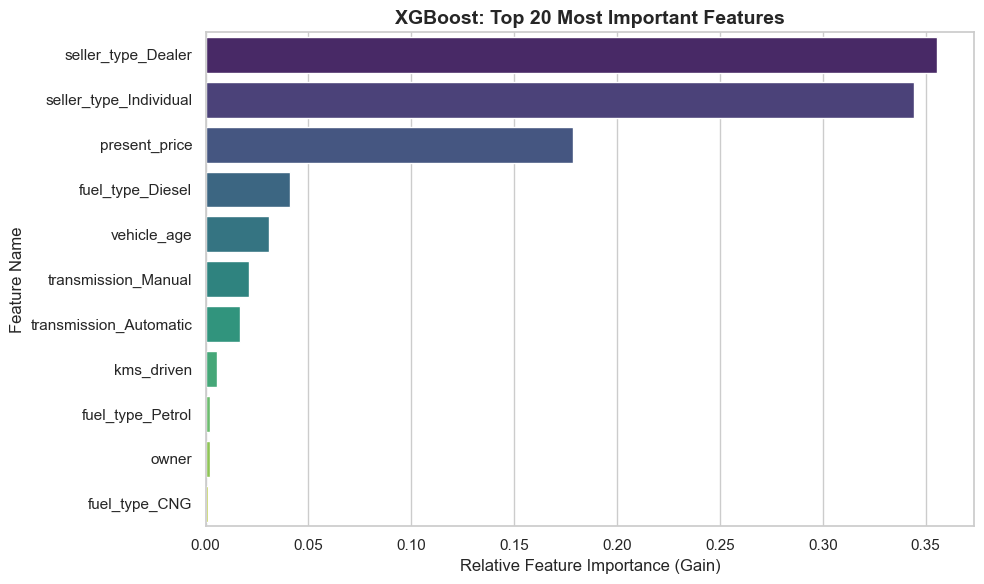

In [12]:
preprocessor = best_pipeline.named_steps['preprocessor']
num_features = preprocessor.transformers_[0][2]
cat_encoder = preprocessor.transformers_[1][1].named_steps['encoder']
cat_features = list(cat_encoder.get_feature_names_out(preprocessor.transformers_[1][2]))
feature_names = num_features + cat_features

xgb_model = best_pipeline.named_steps['model'].regressor_
importances = xgb_model.feature_importances_

feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis', hue='Feature', legend=False)
plt.title('XGBoost: Top 20 Most Important Features', fontsize=14, fontweight='bold')
plt.xlabel('Relative Feature Importance (Gain)', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.tight_layout()
plt.savefig('xgboost_feature_importances.jpg', dpi=300)
plt.show()

### 13. Export Best Model and Save Experiment Summary

In [13]:
joblib.dump(best_pipeline, MODEL_OUTPUT)

results_summary = (
	'XGBoost Hyperparameter Tuning Results\n'
	'===================================\n'
	f'Dataset: {csv_path}\n'
	f'Rows used: {len(X)}\n'
	f'Train rows: {len(X_train)}\n'
	f'Test rows: {len(X_test)}\n'
	f'Best parameters: {best_params}\n'
	f'R²: {metrics["Best R2"]:.6f}\n'
	f'MAE: {metrics["Best MAE"]:.6f}\n'
	f'RMSE: {metrics["Best RMSE"]:.6f}\n'
)
RESULTS_TEXT_OUTPUT.write_text(results_summary, encoding='utf-8')

print(f'[SUCCESS] Serialized best pipeline saved to: {MODEL_OUTPUT.resolve()}')
print(f'[SUCCESS] Experiment results summary saved to: {RESULTS_TEXT_OUTPUT.resolve()}\n')
print(results_summary)

[SUCCESS] Serialized best pipeline saved to: C:\Users\msjan\Desktop\machine learning\best_xgboost_model.joblib
[SUCCESS] Experiment results summary saved to: C:\Users\msjan\Desktop\machine learning\xgboost_hyperparameter_results.txt

XGBoost Hyperparameter Tuning Results
Dataset: cardekho_full.csv
Rows used: 301
Train rows: 240
Test rows: 61
Best parameters: {'model__regressor__subsample': 0.7, 'model__regressor__n_estimators': 800, 'model__regressor__min_child_weight': 1, 'model__regressor__max_depth': 3, 'model__regressor__learning_rate': 0.05, 'model__regressor__gamma': 0, 'model__regressor__colsample_bytree': 0.8}
R²: 0.958109
MAE: 0.565714
RMSE: 0.982334

